<a href="https://colab.research.google.com/github/ramosdannam-beep/analisis-financiero-python/blob/main/analisis_riesgo_aapl_tsla.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

/tmp/ipykernel_2320/3842512676.py:8: FutureWarning: YF.download() has changed argument auto_adjust default to True
  datos = yf.download('AAPL', period='1y')
[*********************100%***********************]  1 of 1 completed


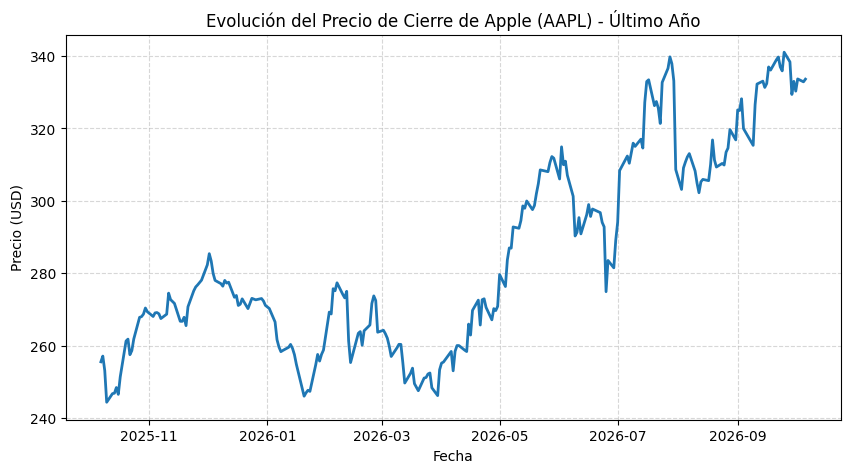


--- RESUMEN EJECUTIVO ---
Precio inicial: $255.54 USD
Precio actual:  $333.63 USD
Volatilidad diaria promedio: 1.56%


In [2]:
# 1. Instalamos la librería para obtener datos financieros reales de Yahoo Finance
!pip install yfinance -q

import yfinance as yf
import matplotlib.pyplot as plt

# 2. Descargamos el historial de precios de Apple (AAPL) del último año
datos = yf.download('AAPL', period='1y')

# 3. Calculamos el rendimiento acumulado
datos['Rendimiento_Diario'] = datos['Close'].pct_change()

# 4. Graficamos el precio de cierre
plt.figure(figsize=(10, 5))
plt.plot(datos['Close'], color='#1f77b4', linewidth=2)
plt.title('Evolución del Precio de Cierre de Apple (AAPL) - Último Año')
plt.xlabel('Fecha')
plt.ylabel('Precio (USD)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# 5. Vemos las métricas básicas
print("\n--- RESUMEN EJECUTIVO ---")
print(f"Precio inicial: ${datos['Close'].iloc[0].item():.2f} USD")
print(f"Precio actual:  ${datos['Close'].iloc[-1].item():.2f} USD")
print(f"Volatilidad diaria promedio: {datos['Rendimiento_Diario'].std() * 100:.2f}%")

/tmp/ipykernel_2320/2228417867.py:9: FutureWarning: YF.download() has changed argument auto_adjust default to True
  datos = yf.download(tickers, period='1y')['Close']
[*********************100%***********************]  2 of 2 completed


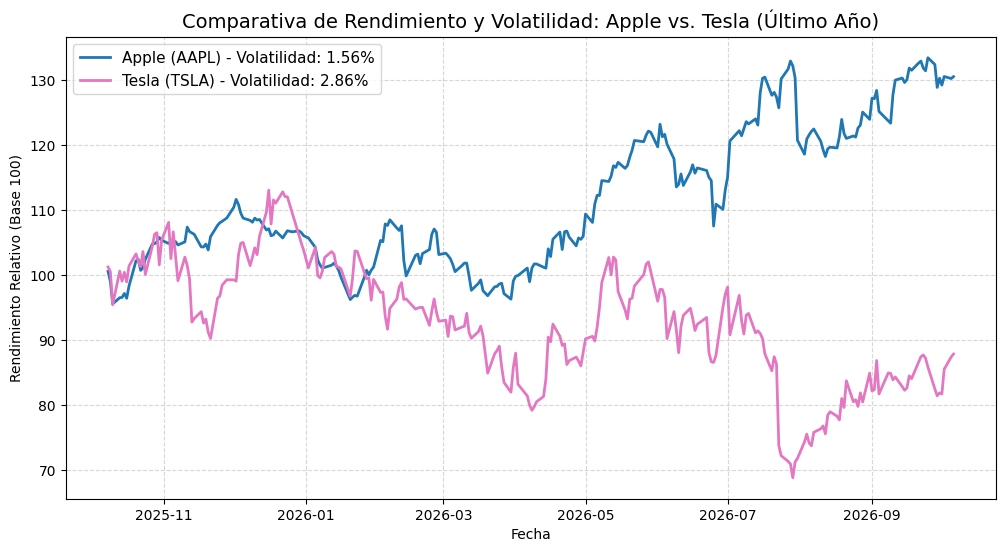


--- DIAGNÓSTICO DE RIESGO Y VOLATILIDAD ---
Volatilidad Diaria Apple (AAPL): 1.56%  | Anualizada: 24.73%
Volatilidad Diaria Tesla (TSLA): 2.86%  | Anualizada: 45.46%
--------------------------------------------------
Diferencia de riesgo: TSLA es aprox. 1.8x más volátil que AAPL.


In [5]:
# 1. Instalamos la librería y descargamos datos de Apple (AAPL) y Tesla (TSLA)
!pip install yfinance -q

import yfinance as yf
import matplotlib.pyplot as plt

# Descargamos 1 año de datos para ambos activos
tickers = ['AAPL', 'TSLA']
datos = yf.download(tickers, period='1y')['Close']

# 2. Calculamos los rendimientos diarios
rendimientos = datos.pct_change().dropna()

# 3. Calculamos la volatilidad diaria de cada activo
vol_aapl = rendimientos['AAPL'].std() * 100
vol_tsla = rendimientos['TSLA'].std() * 100

# 4. Graficamos el rendimiento acumulado (base 100)
rendimiento_acumulado = (1 + rendimientos).cumprod() * 100

plt.figure(figsize=(12, 6))
plt.plot(rendimiento_acumulado['AAPL'], label=f'Apple (AAPL) - Volatilidad: {vol_aapl:.2f}%', color='#1f77b4', linewidth=2)
plt.plot(rendimiento_acumulado['TSLA'], label=f'Tesla (TSLA) - Volatilidad: {vol_tsla:.2f}%', color='#e377c2', linewidth=2)

plt.title('Comparativa de Rendimiento y Volatilidad: Apple vs. Tesla (Último Año)', fontsize=14)
plt.xlabel('Fecha')
plt.ylabel('Rendimiento Relativo (Base 100)')
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# 5. Reporte comparativo impreso
print("\n--- DIAGNÓSTICO DE RIESGO Y VOLATILIDAD ---")
print(f"Volatilidad Diaria Apple (AAPL): {vol_aapl:.2f}%  | Anualizada: {vol_aapl * (252**0.5):.2f}%")
print(f"Volatilidad Diaria Tesla (TSLA): {vol_tsla:.2f}%  | Anualizada: {vol_tsla * (252**0.5):.2f}%")
print("-" * 50)
print(f"Diferencia de riesgo: TSLA es aprox. {(vol_tsla / vol_aapl):.1f}x más volátil que AAPL.")